# 02 · Manifold — principal-curve trajectory (whole malignant manifold)

Li's melanoma manifold is **non-branching**: an elongated single axis (UMAP major/
minor aspect ≈ 7) whose two density poles are biologically identical (settled in 01).
The correct topology is a **principal curve** (ElPiGraph, non-branching by
construction), fit on the whole malignant compartment on its *original joint
embedding* — no re-embedding of the linear compartment. A PPT tree on the same
manifold yields **0 forks**, confirming there is no bifurcation to fit.

In [1]:
%matplotlib inline
import os, sys, glob, re, io, contextlib, warnings
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
import scipy.sparse as sp
from scipy.sparse.csgraph import shortest_path
from scipy.stats import spearmanr
from numpy.linalg import svd
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd()); cat = os.path.basename(os.path.dirname(os.getcwd()))
pth = os.path.join(*([os.pardir]*4)); pth_data = os.path.join(pth,'data')
pth_out = os.path.join(pth_data,'cancer', 'vertebrate', 'CCCA', 'claude',cat,name)
pth_feat = os.path.join(pth_data,'features','biomart')
pth_fig = os.path.join(pth,'figures', 'mesencontext', 'claude',cat,name)
pth_cb = os.path.join(pth_fig,'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)

### Load processed manifold; confirm elongated (1-D) geometry

In [3]:
adata = sc.read_h5ad(os.path.join(pth_out,'processed.h5ad'))
xy = adata.obsm['X_umap']; c = xy - xy.mean(0); _,s,_ = svd(c, full_matrices=False)
print('malignant manifold:', adata.shape[0], 'cells | UMAP aspect (major/minor std): %.2f'%(s[0]/s[1]))

malignant manifold: 1082 cells | UMAP aspect (major/minor std): 7.50


### Score embryonic modules + graph-smooth for geography
The three developmental signatures are scored against the shared **union** control
pool, then graph-smoothed (kNN averaging) so geography and the root are read from
neighbourhood trends rather than single-cell dropout (MARS-seq is shallow).

In [4]:
feat = {os.path.basename(f).replace('.csv',''): pd.read_csv(f).hsapiens.drop_duplicates()
        for f in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
g_ref = feat['union'].loc[feat['union'].isin(adata.var_names)]
for src,lab in [('GSE162534','Gast'),('GSE229103','pSom'),('rRNAModifications','Crest')]:
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    sc.tl.score_genes(adata, gene_list=g, score_name=lab, ctrl_as_ref=False,
                      gene_pool=g_ref, random_state=1234)
    print(f'{lab}: {g.size}/{feat[src].size} genes present | mean={adata.obs[lab].mean():+.4f}')
A = (adata.obsp['connectivities']>0).astype(float); A = A + sp.eye(A.shape[0])
A = sp.diags(1/np.array(A.sum(1)).ravel()) @ A
S = adata.obs[['Gast','pSom','Crest']].values.copy()
for _ in range(3): S = A @ S
for j,lab in enumerate(['Gast','pSom','Crest']): adata.obs[lab+'_sm'] = S[:,j]

Gast: 64/81 genes present | mean=-0.0152
pSom: 75/98 genes present | mean=+0.0158
Crest: 96/104 genes present | mean=-0.0022


### Fit the principal curve (ElPiGraph) + confirm no bifurcation
`fold_diag` reports tips, forks, and a node self-approach ratio (>1 = fold-free).
A curve gives 2 tips / 0 forks; a PPT tree on the same manifold also yields 0 forks
— there is no hub-and-spoke bifurcation, so the curve is the correct topology.

In [5]:
def fold_diag(a):
    B = np.asarray(a.uns['graph']['B']); F = a.uns['graph']['F'].T
    G = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
    ii,jj = np.where(np.triu(B>0)); med = np.median(np.sqrt(((F[ii]-F[jj])**2).sum(1)))
    dmin = np.inf
    for x in range(F.shape[0]):
        for y in range(x+1, F.shape[0]):
            if G[x,y] >= 3: dmin = min(dmin, np.sqrt(((F[x]-F[y])**2).sum()))
    return dmin/med, int(((B>0).sum(0)==1).sum()), int(((B>0).sum(0)>=3).sum())
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.curve(adata, Nodes=20, use_rep='X_umap', epg_lambda=0.3, epg_mu=100.0, seed=SEED, plot=False)
sa, tips, forks = fold_diag(adata)
print(f'CURVE: {tips} tips, {forks} forks | fold self-approach = {sa:.2f} (>1 fold-free)')
tree_probe = adata.copy()
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.tree(tree_probe, method='ppt', Nodes=50, ppt_lambda=2000, ppt_sigma=.5,
                use_rep='X_umap', seed=SEED, plot=False)
Bt = np.asarray(tree_probe.uns['graph']['B'])
print(f'PPT tree probe (Nodes=50): {int((Bt>0).sum(0).__eq__(1).sum())} tips, {int(((Bt>0).sum(0)>=3).sum())} forks -> no bifurcation')
assert forks == 0 and sa > 1, 'topology check failed'

CURVE: 2 tips, 0 forks | fold self-approach = 2.99 (>1 fold-free)
PPT tree probe (Nodes=50): 2 tips, 0 forks -> no bifurcation


### Root from the developmental signature order + pseudotime
Root at the curve tip whose neighbourhood is **Gast/pSom-high & Crest-low** — the
gastrulation origin. Crest is developmentally *late* and never the root.

In [6]:
B = np.asarray(adata.uns['graph']['B']); tps = np.where((B>0).sum(0)==1)[0]
R = np.asarray(adata.obsm['X_R']); hard = R.argmax(1)
D = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
info = {}
for t in tps:
    m = np.isin(hard, np.where(D[t]<=3)[0])
    info[t] = (adata.obs['Gast_sm'][m].mean(), adata.obs['pSom_sm'][m].mean(), adata.obs['Crest_sm'][m].mean())
    print(f'tip {t}: Gast={info[t][0]:+.4f} pSom={info[t][1]:+.4f} Crest={info[t][2]:+.4f}')
root = int(max(tps, key=lambda t: info[t][0] + info[t][1] - info[t][2]))
print('derived root = tip', root, '(Gast/pSom-high, Crest-low origin)')
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.root(adata, root); scf.tl.pseudotime(adata, n_map=1, seed=SEED)
t = adata.obs['t'].values
print('gradient along pseudotime (Spearman rho, smoothed):')
for s in ['Gast_sm','pSom_sm','Crest_sm']:
    rho,p = spearmanr(t, adata.obs[s]); print(f'  {s}: rho={rho:+.3f} p={p:.1e}')

tip 0: Gast=-0.0133 pSom=+0.0147 Crest=-0.0048
tip 2: Gast=-0.0165 pSom=+0.0132 Crest=+0.0031
derived root = tip 0 (Gast/pSom-high, Crest-low origin)
gradient along pseudotime (Spearman rho, smoothed):
  Gast_sm: rho=-0.469 p=2.2e-60
  pSom_sm: rho=+0.052 p=8.5e-02
  Crest_sm: rho=+0.586 p=6.2e-101


### Reorient to house style (pseudotime left → right)
Discrete x-flip only (no rotation) on the raw UMAP; the curve's major axis is already
horizontal, so a single flip places the Gast-high root at the left. Continuity/fold
is judged from the curve's own self-approach ratio above (an independent graph
metric), not from neighbours read off this UMAP.

In [7]:
xy = adata.obsm['X_umap'].copy(); t = adata.obs['t'].values
r = float(np.corrcoef(xy[:,0], t)[0,1])
xyr = np.column_stack([xy[:,0] if r>0 else -xy[:,0], xy[:,1]])
r2 = float(np.corrcoef(xyr[:,0], t)[0,1]); assert r2 > 0
adata.obsm['X_umap_lin'] = xyr
print(f'orientation: x-flip; corr(x_lin, pseudotime) = {r2:+.2f}')

orientation: x-flip; corr(x_lin, pseudotime) = +1.00


### Save manifold + trajectory figure (deliverable `manifold.pdf`)

saved manifold.h5ad + manifold.pdf


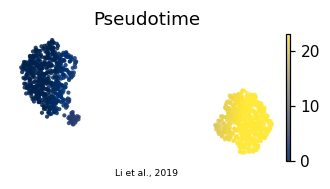

In [8]:
adata.uns['epg'] = {'NodePositions': np.asarray(adata.uns['epg']['NodePositions'])}
adata.write(os.path.join(pth_out,'manifold.h5ad'))
plot = adata.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
xl = plot.obsm['X_umap']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, color='t', cmap='cividis', size=30, alpha=.85, colorbar_loc='right',
           frameon=False, show=False, ax=ax, title='Pseudotime')
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
ax.text(.5,-.12,'Li et al., 2019', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'manifold.pdf'), bbox_inches='tight')
print('saved manifold.h5ad + manifold.pdf')